In [1]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

print("Dataset Shape:")
print(df.shape)
print()

print("Missing Value Counts:")
print(df.isnull().sum())
print()

print("Column Means:")
print(df.mean(numeric_only=True))

Dataset Shape:
(50, 6)

Missing Value Counts:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Column Means:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


Prompt log

Prompt 1: You are helping with exploratory data analysis.
My CSV has columns: Contry (object), sr (float64), pop15 (float64), pop75 (float64), dpi (float64), ddpi (float64).
Write Python using pandas, scikit-learn, and seaborn to:
(1) summarize missing data,
(2) scale the numeric features and apply K-Means clustering to group the countries by their savings and economic behavior,
(3) produce a scatter plot visualization showing the clusters with clear labels.
Explain each step in comments.

results: The ai's scatter plot matches my groupby.

--- Missing Data Summary ---
        Missing Count  Missing Percentage (%)
Contry              0                     0.0
sr                  0                     0.0
pop15               0                     0.0
pop75               0                     0.0
dpi                 0                     0.0
ddpi                0                     0.0


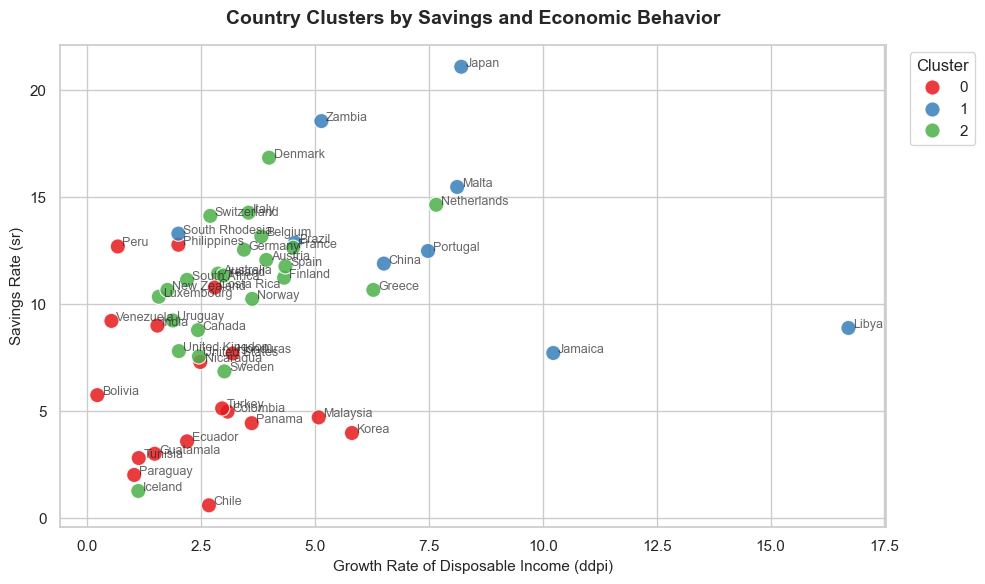

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Assuming your DataFrame is named 'df'
# df = pd.read_csv('your_dataset.csv')

# ==========================================
# (1) Summarize Missing Data
# ==========================================
# Calculate total missing values and percentage per column
missing_summary = pd.DataFrame(
    {
        'Missing Count': df.isnull().sum(),
        'Missing Percentage (%)': (df.isnull().mean() * 100).round(2),
    }
)

print('--- Missing Data Summary ---')
print(missing_summary)

# Drop rows with missing values in the numeric feature columns required for clustering
numeric_features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
df_clean = df.dropna(subset=numeric_features).copy()

# ==========================================
# (2) Scale Features & Apply K-Means Clustering
# ==========================================
# Initialize the standard scaler to normalize features (mean=0, variance=1)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clean[numeric_features])

# Apply K-Means clustering (choosing k=3 as an exploratory starting point)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(scaled_data)

# ==========================================
# (3) Scatter Plot Visualization
# ==========================================
plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

# Create a scatter plot mapping Savings Rate (sr) against Growth Rate of Disposable Income (ddpi)
sns.scatterplot(
    data=df_clean,
    x='ddpi',
    y='sr',
    hue='Cluster',
    palette='Set1',
    s=120,
    alpha=0.85,
    edgecolor='w',
)

# Annotate points with country names for clear identification
for i, row in df_clean.iterrows():
  plt.text(
      row['ddpi'] + 0.1,
      row['sr'],
      str(row['Contry']),
      fontsize=9,
      alpha=0.7,
  )

plt.title(
    'Country Clusters by Savings and Economic Behavior',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Growth Rate of Disposable Income (ddpi)', fontsize=11)
plt.ylabel('Savings Rate (sr)', fontsize=11)
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [3]:
cluster_means = df_clean.groupby('Cluster').mean(numeric_only=True)

target_cluster = 0
print(cluster_means.loc[target_cluster])

sr         6.138889
pop15     44.556111
pop75      1.079444
dpi      337.153333
ddpi       2.359444
Name: 0, dtype: float64


There are 3 clusters and they seem to represent three different categories based on how people save money and how their economies are growing. The biggest issue in my opinion with using ai to do things that you do not fully undertstand, is that it is hard to tell when it is wrong. If you do not know how to recognise mistakes then ai can do things incorrectly in a way that you cannot recognize, and then you do not learn how to do things correctly.